# Analiza danych Tennessee Eastman Process (TEP)
## cz. I

Projekt z przedmiotu *Eksploracja Danych w Systemach Automatyki*. \
**Autor:** Ewa Kasprzak 272356 \
**Wykorzystany zbiór danych:** https://www.kaggle.com/datasets/afrniomelo/tep-csv

## 1. Wczytanie danych

Zachowujemy dostarczony podział na zbiór treningowy i testowy.
Zgodnie z opisem projektu wykorzystujemy **30 symulacji** dla każdej klasy
(stan normalny + wybrane typy awarii).

In [1]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path("data")

# Wybrane klasy: 0 = normalna praca + 5 typów awarii
# (4, 6, 8, 13, 15 - te same wymagane później w etapie wykrywania anomalii)
FAULT_NUMBERS = [0, 4, 6, 8, 13, 15]
N_SIMULATIONS = 30  # liczba symulacji na klasę

META_COLS = ["faultNumber", "simulationRun", "sample"]

### Funkcja pomocnicza

Pliki `Faulty_*` są bardzo duże, więc wczytujemy je porcjami i od razu filtrujemy wybrane awarie oraz pierwsze `N_SIMULATIONS` przebiegów.

In [2]:
def load_tep_subset(
    fault_free_path: Path,
    faulty_path: Path,
    fault_numbers: list[int],
    n_simulations: int,
    chunksize: int = 200_000,
) -> pd.DataFrame:
    frames: list[pd.DataFrame] = []

    # Stan normalny (faultNumber = 0)
    if 0 in fault_numbers:
        ff = pd.read_csv(fault_free_path)
        ff = ff[ff["simulationRun"] <= n_simulations]
        frames.append(ff)

    # Wybrane awarie
    selected_faults = [f for f in fault_numbers if f != 0]
    if selected_faults:
        for chunk in pd.read_csv(faulty_path, chunksize=chunksize):
            mask = (
                chunk["faultNumber"].isin(selected_faults)
                & (chunk["simulationRun"] <= n_simulations)
            )
            filtered = chunk.loc[mask]
            if not filtered.empty:
                frames.append(filtered)

    df = pd.concat(frames, ignore_index=True)
    df = df.sort_values(["faultNumber", "simulationRun", "sample"]).reset_index(drop=True)
    return df

### Zbiór treningowy

- `TEP_FaultFree_Training.csv` - normalna praca
- `TEP_Faulty_Training.csv` - awarie
- 500 próbek na symulację; oczekiwany rozmiar: $6 \times 30 \times 500 = 90\,000$ obserwacji

In [3]:
train = load_tep_subset(
    DATA_DIR / "TEP_FaultFree_Training.csv",
    DATA_DIR / "TEP_Faulty_Training.csv",
    fault_numbers=FAULT_NUMBERS,
    n_simulations=N_SIMULATIONS,
)

print(f"Zbiór treningowy: {train.shape[0]:,} wierszy x {train.shape[1]} kolumn")
print(f"Klasy: {sorted(train['faultNumber'].unique().tolist())}")
print(f"Liczba symulacji na klasę:\n{train.groupby('faultNumber')['simulationRun'].nunique()}")
print(f"Liczba próbek na symulację (min/max): "
      f"{train.groupby(['faultNumber','simulationRun']).size().min()} / "
      f"{train.groupby(['faultNumber','simulationRun']).size().max()}")
train.head()

Zbiór treningowy: 90,000 wierszy x 55 kolumn
Klasy: [0, 4, 6, 8, 13, 15]
Liczba symulacji na klasę:
faultNumber
0     30
4     30
6     30
8     30
13    30
15    30
Name: simulationRun, dtype: int64
Liczba próbek na symulację (min/max): 500 / 500


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0,1,1,0.25038,3674.0,4529.0,9.2320,26.889,42.402,2704.3,...,53.744,24.657,62.544,22.137,39.935,42.323,47.757,47.510,41.258,18.447
1,0,1,2,0.25109,3659.4,4556.6,9.4264,26.721,42.576,2705.0,...,53.414,24.588,59.259,22.084,40.176,38.554,43.692,47.427,41.359,17.194
2,0,1,3,0.25038,3660.3,4477.8,9.4426,26.875,42.070,2706.2,...,54.357,24.666,61.275,22.380,40.244,38.990,46.699,47.468,41.199,20.530
3,0,1,4,0.24977,3661.3,4512.1,9.4776,26.758,42.063,2707.2,...,53.946,24.725,59.856,22.277,40.257,38.072,47.541,47.658,41.643,18.089
4,0,1,5,0.29405,3679.0,4497.0,9.3381,26.889,42.650,2705.1,...,53.658,28.797,60.717,21.947,39.144,41.955,47.645,47.346,41.507,18.461


### Zbiór testowy

- `TEP_FaultFree_Testing.csv` - normalna praca
- `TEP_Faulty_Testing.csv` - awarie
- 960 próbek na symulację; oczekiwany rozmiar: $6 \times 30 \times 960 = 172\,800$ obserwacji
- W danych testowych awaria zaczyna się od `sample = 160`

In [4]:
test = load_tep_subset(
    DATA_DIR / "TEP_FaultFree_Testing.csv",
    DATA_DIR / "TEP_Faulty_Testing.csv",
    fault_numbers=FAULT_NUMBERS,
    n_simulations=N_SIMULATIONS,
)

print(f"Zbiór testowy: {test.shape[0]:,} wierszy × {test.shape[1]} kolumn")
print(f"Klasy: {sorted(test['faultNumber'].unique().tolist())}")
print(f"Liczba symulacji na klasę:\n{test.groupby('faultNumber')['simulationRun'].nunique()}")
print(f"Liczba próbek na symulację (min/max): "
      f"{test.groupby(['faultNumber','simulationRun']).size().min()} / "
      f"{test.groupby(['faultNumber','simulationRun']).size().max()}")
test.head()

Zbiór testowy: 172,800 wierszy × 55 kolumn
Klasy: [0, 4, 6, 8, 13, 15]
Liczba symulacji na klasę:
faultNumber
0     30
4     30
6     30
8     30
13    30
15    30
Name: simulationRun, dtype: int64
Liczba próbek na symulację (min/max): 960 / 960


,faultNumber,simulationRun,sample,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,xmeas_7,...,xmv_2,xmv_3,xmv_4,xmv_5,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0,1,1,0.25171,3672.4,4466.3,9.5122,27.057,42.473,2705.6,...,54.494,24.527,59.710,22.357,40.149,40.074,47.955,47.300,42.100,15.345
1,0,1,2,0.25234,3642.2,4568.7,9.4145,26.999,42.586,2705.2,...,53.269,24.465,60.466,22.413,39.956,36.651,45.038,47.502,40.553,16.063
2,0,1,3,0.24840,3643.1,4507.5,9.2901,26.927,42.278,2703.5,...,54.000,24.860,60.642,22.199,40.074,41.868,44.553,47.479,41.341,20.452
3,0,1,4,0.25153,3628.3,4519.3,9.3347,26.999,42.330,2703.9,...,53.860,24.553,61.908,21.981,40.141,40.066,48.048,47.440,40.780,17.123
4,0,1,5,0.21763,3655.8,4571.0,9.3087,26.901,42.402,2707.7,...,53.307,21.775,61.891,22.412,37.696,38.295,44.678,47.530,41.089,18.681


### Podsumowanie wczytania

In [5]:
process_cols = [c for c in train.columns if c not in META_COLS]

summary = pd.DataFrame(
    {
        "zbiór": ["treningowy", "testowy"],
        "obserwacje": [len(train), len(test)],
        "kolumny": [train.shape[1], test.shape[1]],
        "zmienne procesowe": [len(process_cols), len(process_cols)],
        "klasy": [train["faultNumber"].nunique(), test["faultNumber"].nunique()],
        "symulacje na klasę": [N_SIMULATIONS, N_SIMULATIONS],
    }
)
summary

,zbiór,obserwacje,kolumny,zmienne procesowe,klasy,symulacje na klasę
0,treningowy,90000,55,52,6,30
1,testowy,172800,55,52,6,30


## 2. Opis struktury zbioru

Każda obserwacja zawiera **55 kolumn**:
- **3 zmienne pomocnicze** - `faultNumber`, `simulationRun`, `sample`
- **52 zmienne procesowe** - `xmeas_*` (wartości mierzone) oraz `xmv_*` (sygnały sterujące)

In [6]:
xmeas_cols = [c for c in process_cols if c.startswith("xmeas_")]
xmv_cols = [c for c in process_cols if c.startswith("xmv_")]

print("=== Struktura kolumn ===")
print(f"Łącznie kolumn:           {train.shape[1]}")
print(f"Zmienne pomocnicze:       {len(META_COLS)}: {META_COLS}")
print(f"Zmienne procesowe:        {len(process_cols)}")
print(f"  - xmeas (mierzone):     {len(xmeas_cols)}")
print(f"  - xmv   (sterujące):    {len(xmv_cols)}")
print()
print("=== Liczba obserwacji ===")
print(f"Trening:  {len(train):,}  (= {train['faultNumber'].nunique()} klas x "
      f"{N_SIMULATIONS} sym. x {train.groupby(['faultNumber','simulationRun']).size().iloc[0]} próbek)")
print(f"Test:     {len(test):,}  (= {test['faultNumber'].nunique()} klas x "
      f"{N_SIMULATIONS} sym. x {test.groupby(['faultNumber','simulationRun']).size().iloc[0]} próbek)")
print(f"Razem:    {len(train) + len(test):,}")

=== Struktura kolumn ===
Łącznie kolumn:           55
Zmienne pomocnicze:       3: ['faultNumber', 'simulationRun', 'sample']
Zmienne procesowe:        52
  - xmeas (mierzone):     41
  - xmv   (sterujące):    11

=== Liczba obserwacji ===
Trening:  90,000  (= 6 klas x 30 sym. x 500 próbek)
Test:     172,800  (= 6 klas x 30 sym. x 960 próbek)
Razem:    262,800


### Typy danych i znaczenie zmiennych pomocniczych

In [7]:
print("Typy danych (zbiór treningowy):")
print(train.dtypes.value_counts().to_string())
print()
print("Typy zmiennych pomocniczych::")
print(train[META_COLS].dtypes.to_string())
print()
print("Typy zmiennych procesowych:")
print(train[process_cols].dtypes.to_string())

Typy danych (zbiór treningowy):
float64    52
int64       3

Typy zmiennych pomocniczych::
faultNumber      int64
simulationRun    int64
sample           int64

Typy zmiennych procesowych:
xmeas_1     float64
xmeas_2     float64
xmeas_3     float64
xmeas_4     float64
xmeas_5     float64
xmeas_6     float64
xmeas_7     float64
xmeas_8     float64
xmeas_9     float64
xmeas_10    float64
xmeas_11    float64
xmeas_12    float64
xmeas_13    float64
xmeas_14    float64
xmeas_15    float64
xmeas_16    float64
xmeas_17    float64
xmeas_18    float64
xmeas_19    float64
xmeas_20    float64
xmeas_21    float64
xmeas_22    float64
xmeas_23    float64
xmeas_24    float64
xmeas_25    float64
xmeas_26    float64
xmeas_27    float64
xmeas_28    float64
xmeas_29    float64
xmeas_30    float64
xmeas_31    float64
xmeas_32    float64
xmeas_33    float64
xmeas_34    float64
xmeas_35    float64
xmeas_36    float64
xmeas_37    float64
xmeas_38    float64
xmeas_39    float64
xmeas_40    float64
xmeas_41   

## 3. Eksploracyjna analiza danych (EDA)

### 3.1. Analiza statystyczna

Podstawowe statystyki wyznaczamy dla **wszystkich 52 zmiennych procesowych**
na zbiorze treningowym w **stanie normalnym** (`faultNumber = 0`), zgodnie z wytycznymi projektu.

Obliczamy: średnią, medianę, odchylenie standardowe, min, max, Q1, Q3
oraz dodatkowo **skośność (skewness)**, która pozwala ocenić, czy rozkład jest zbliżony do symetrycznego (wartości bliskie 0), czy wyraźnie skośny.

In [8]:
from pathlib import Path

TABLE_DIR = Path("tables")
TABLE_DIR.mkdir(exist_ok=True)


def save_latex_table(
    df: pd.DataFrame,
    path: Path,
    caption: str,
    label: str,
    float_format: str = "%.3f",
) -> None:
    """Zapisz DataFrame jako tabelę LaTeX."""
    body = df.to_latex(
        escape=True,
        float_format=float_format,
        column_format="l" + "r" * df.shape[1],
        index=True,
        index_names=False,
    )
    content = (
        "\\begin{table}[ht]\n"
        "\\centering\n"
        f"\\caption{{{caption}}}\n"
        f"\\label{{{label}}}\n"
        "\\scriptsize\n"
        f"{body}"
        "\\end{table}\n"
    )
    path.write_text(content, encoding="utf-8")
    print(f"LaTeX: {path}")


train_normal = train.loc[train["faultNumber"] == 0, process_cols]

stats = train_normal.agg(
    ["mean", "median", "std", "min", "max",
     lambda s: s.quantile(0.25), lambda s: s.quantile(0.75), "skew"]
).T
stats.columns = ["mean", "median", "std", "min", "max", "Q1", "Q3", "skewness"]
stats = stats.round(4)

STAT_COLS = ["mean", "median", "std", "min", "max", "Q1", "Q3", "skewness"]
COL_RENAME = {
    "mean": "Średnia",
    "median": "Mediana",
    "std": "Odch. std",
    "min": "Min",
    "max": "Max",
    "Q1": "Q1",
    "Q3": "Q3",
    "skewness": "Skośność",
}
stats_full = stats[STAT_COLS].rename(columns=COL_RENAME)

print(f"Statystyki dla stanu normalnego — {len(train_normal):,} obserwacji, {len(process_cols)} zmiennych")

save_latex_table(
    stats_full,
    TABLE_DIR / "stats_normal_full.tex",
    caption="Statystyki opisowe wszystkich 52 zmiennych procesowych w stanie normalnym (zbiór treningowy).",
    label="tab:stats-normal-full",
    float_format="%.4f",
)

stats_full

Statystyki dla stanu normalnego — 15,000 obserwacji, 52 zmiennych
LaTeX: tables/stats_normal_full.tex


,Średnia,Mediana,Odch. std,Min,Max,Q1,Q3,Skośność
xmeas_1,0.2504,0.2507,0.0309,0.1313,0.3632,0.2303,0.2709,-0.0400
xmeas_2,3663.0672,3662.5000,34.4103,3527.8000,3787.6000,3639.9000,3686.3000,0.0344
xmeas_3,4509.2525,4508.8000,39.7062,4354.8000,4663.8000,4482.7000,4535.8000,0.0081
xmeas_4,9.3477,9.3479,0.0876,9.0353,9.6613,9.2886,9.4072,0.0168
xmeas_5,26.9003,26.9010,0.2116,26.1820,27.7850,26.7578,27.0460,-0.0230
xmeas_6,42.3366,42.3380,0.2202,41.5120,43.2570,42.1850,42.4890,-0.0151
xmeas_7,2705.4425,2705.5000,7.8801,2679.5000,2731.9000,2700.2000,2710.8000,-0.0203
xmeas_8,74.9949,74.9970,0.5468,72.9360,77.5140,74.6260,75.3692,-0.0212
xmeas_9,120.4001,120.4000,0.0192,120.3200,120.4800,120.3900,120.4100,-0.0121
xmeas_10,0.3370,0.3370,0.0126,0.2871,0.3841,0.3288,0.3454,0.0315


### Skośność: czy rozkłady są symetryczne?

**|s| ≈ 0** symetryczny, **s > 0** prawostronnie skośny, **s < 0** lewostronnie skośny.

Przy **|s| < 0.5** skośność traktujemy jako w praktyce pomijalną (rozkład prawie symetryczny).

In [9]:
import matplotlib.pyplot as plt

COLOR_PINK = "#E91E8C"
COLOR_BLUE = "#1565C0"
COLOR_GREEN = "#2E7D32"

skew = stats["skewness"]
abs_skew = skew.abs()

n_right = int((skew > 0).sum())   # prawostronnie skośne
n_left = int((skew < 0).sum())    # lewostronnie skośne
n_zero = int((skew == 0).sum())
n_near_sym = int((abs_skew < 0.5).sum())  # praktycznie symetryczne

print("Kierunek skośności (znak):")
print(f"  prawostronne (s > 0): {n_right}")
print(f"  lewostronne  (s < 0): {n_left}")
print(f"  dokładnie 0:         {n_zero}")
print()
print(f"Prawie symetryczne (|s| < 0.5): {n_near_sym} / {len(skew)}")
print()
print("Top 5 najbardziej prawostronnych (s > 0):")
print(skew.nlargest(5).round(4).to_string())
print()
print("Top 5 najbardziej lewostronnych (s < 0):")
print(skew.nsmallest(5).round(4).to_string())

Kierunek skośności (znak):
  prawostronne (s > 0): 27
  lewostronne  (s < 0): 25
  dokładnie 0:         0

Prawie symetryczne (|s| < 0.5): 52 / 52

Top 5 najbardziej prawostronnych (s > 0):
xmv_9       0.1065
xmeas_29    0.0611
xmeas_39    0.0508
xmeas_41    0.0411
xmeas_14    0.0387

Top 5 najbardziej lewostronnych (s < 0):
xmeas_31   -0.0960
xmeas_26   -0.0466
xmeas_37   -0.0461
xmeas_25   -0.0451
xmv_3      -0.0416


Wykres skośności: **niebieski** = prawostronna (`s > 0`), **różowy** = lewostronna (`s < 0`). Linie przerywane (zielone) = próg +/- 0.5.

Skośność max (prawostronna): 0.1065
Skośność min (lewostronna):  -0.0960
Zapisano: figures/skewness_normal.png


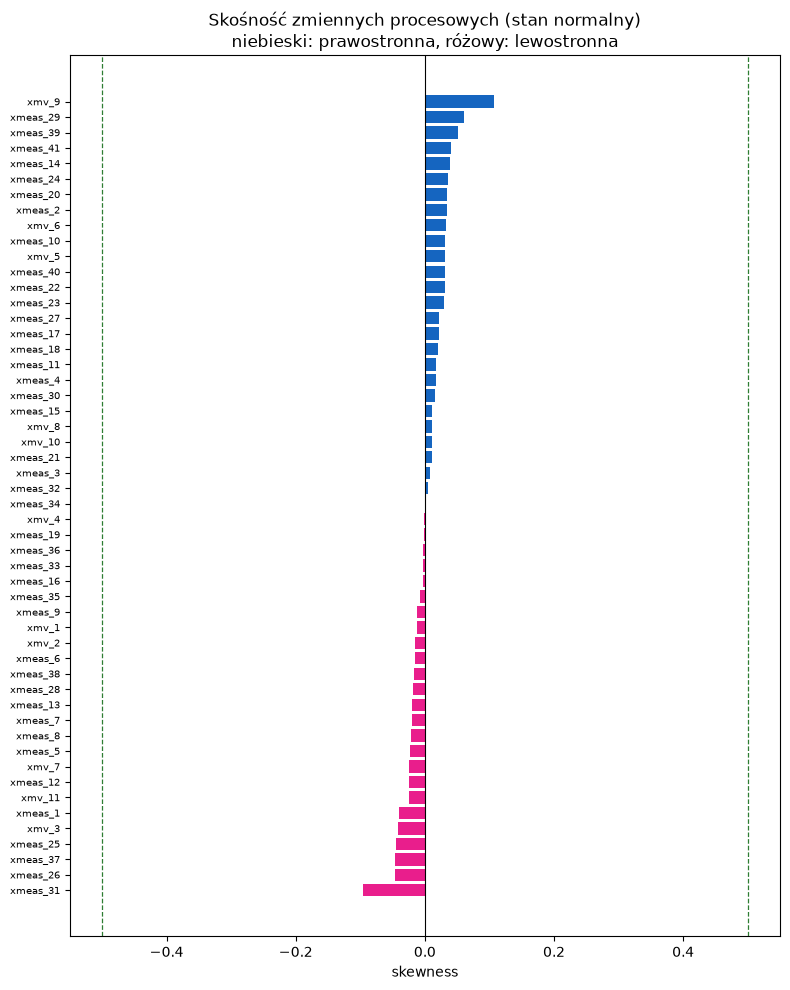

In [10]:
from pathlib import Path

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

skew_sorted = stats["skewness"].sort_values()
print(f"Skośność max (prawostronna): {skew_sorted.max():.4f}")
print(f"Skośność min (lewostronna):  {skew_sorted.min():.4f}")

colors = [COLOR_BLUE if v > 0 else COLOR_PINK if v < 0 else COLOR_GREEN for v in skew_sorted]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(skew_sorted.index, skew_sorted.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.axvline(-0.5, color=COLOR_GREEN, ls="--", lw=0.9)
ax.axvline(0.5, color=COLOR_GREEN, ls="--", lw=0.9)
ax.set_xlabel("skewness")
ax.set_title("Skośność zmiennych procesowych (stan normalny)\nniebieski: prawostronna, różowy: lewostronna")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()

fig_path = FIG_DIR / "skewness_normal.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()

### Średnia vs mediana

Jeśli punkty leżą blisko linii `mean = median`, rozkłady są symetryczne.

Zapisano: figures/mean_median_normal.png


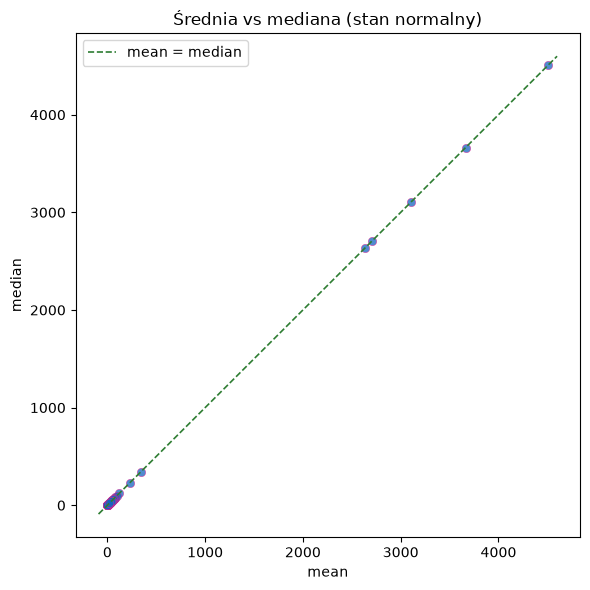

Największe |mean - median|:
xmeas_2     0.5672
xmeas_19    0.5118
xmeas_3     0.4525
xmv_9       0.1730
xmeas_13    0.1208


In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(
    stats["mean"], stats["median"],
    alpha=0.75, color=COLOR_BLUE, edgecolors=COLOR_PINK, linewidths=0.4,
)

lo = min(stats["mean"].min(), stats["median"].min())
hi = max(stats["mean"].max(), stats["median"].max())
pad = 0.02 * (hi - lo + 1e-9)
ax.plot(
    [lo - pad, hi + pad], [lo - pad, hi + pad],
    color=COLOR_GREEN, ls="--", lw=1.2, label="mean = median",
)

ax.set_xlabel("mean")
ax.set_ylabel("median")
ax.set_title("Średnia vs mediana (stan normalny)")
ax.legend()
plt.tight_layout()

fig_path = FIG_DIR / "mean_median_normal.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")

plt.show()

print("Największe |mean - median|:")
print((stats["mean"] - stats["median"]).abs().nlargest(5).round(4).to_string())

### Przegląd wartości każdej statystyki

Dla każdej miary: zmienne z **największymi** i **najmniejszymi** wartościami oraz **średnia** tej miary po wszystkich 52 zmiennych.

In [12]:
N_SHOW = 1  # top n największych i najmniejszych wartości

rows = []
for col in STAT_COLS:
    s = stats[col]
    top = s.nlargest(N_SHOW)
    bot = s.nsmallest(N_SHOW)
    print(f"=== {col} ===")
    print(f"średnia po zmiennych: {s.mean():.4f}")
    print("największe:")
    print(top.round(4).to_string())
    print("najmniejsze:")
    print(bot.round(4).to_string())
    print()
    rows.append(
        {
            "statystyka": COL_RENAME[col],
            "średnia": round(s.mean(), 4),
            **{f"max_{i+1}": f"{val:.4f} ({idx})" for i, (idx, val) in enumerate(top.items())},
            **{f"min_{i+1}": f"{val:.4f} ({idx})" for i, (idx, val) in enumerate(bot.items())},
        }
    )

stats_extremes = pd.DataFrame(rows).set_index("statystyka")
save_latex_table(
    stats_extremes,
    TABLE_DIR / "stats_normal_extremes.tex",
    caption="Największe i najmniejsze wartości każdej statystyki oraz średnia po zmiennych (stan normalny).",
    label="tab:stats-extremes",
    float_format="%.4f",
)
stats_extremes

=== mean ===
średnia po zmiennych: 359.2137
największe:
xmeas_3    4509.2525
najmniejsze:
xmeas_37    0.0178

=== median ===
średnia po zmiennych: 359.1848
największe:
xmeas_3    4508.8
najmniejsze:
xmeas_37    0.0179

=== std ===
średnia po zmiennych: 2.6305
największe:
xmeas_3    39.7062
najmniejsze:
xmeas_37    0.0099

=== min ===
średnia po zmiennych: 349.3073
największe:
xmeas_3    4354.8
najmniejsze:
xmeas_37   -0.0143

=== max ===
średnia po zmiennych: 368.9132
największe:
xmeas_3    4663.8
najmniejsze:
xmeas_37    0.055

=== Q1 ===
średnia po zmiennych: 357.4710
największe:
xmeas_3    4482.7
najmniejsze:
xmeas_37    0.0111

=== Q3 ===
średnia po zmiennych: 360.9708
największe:
xmeas_3    4535.8
najmniejsze:
xmeas_37    0.0245

=== skewness ===
średnia po zmiennych: 0.0035
największe:
xmv_9    0.1065
najmniejsze:
xmeas_31   -0.096

LaTeX: tables/stats_normal_extremes.tex


,średnia,max_1,min_1
statystyka,,,
Średnia,359.2137,4509.2525 (xmeas_3),0.0178 (xmeas_37)
Mediana,359.1848,4508.8000 (xmeas_3),0.0179 (xmeas_37)
Odch. std,2.6305,39.7062 (xmeas_3),0.0099 (xmeas_37)
Min,349.3073,4354.8000 (xmeas_3),-0.0143 (xmeas_37)
Max,368.9132,4663.8000 (xmeas_3),0.0550 (xmeas_37)
Q1,357.4710,4482.7000 (xmeas_3),0.0111 (xmeas_37)
Q3,360.9708,4535.8000 (xmeas_3),0.0245 (xmeas_37)
Skośność,0.0035,0.1065 (xmv_9),-0.0960 (xmeas_31)


### 3.2. Analiza korelacji

Liczymy korelację **Pearsona** dla wszystkich 52 zmiennych procesowych
w stanie normalnym (`train_normal`).

Progi interpretacji `|r|` zgodnie z https://statystyka.org.pl/1-korelacja-pearsona-kiedy-stosowac-i-jak-interpretowac-wynik/:
- **>= 0.5** - silna zależność liniowa
- **0.3 - 0.49** - umiarkowana
- **< 0.3** - słaba

In [13]:
import numpy as np
import seaborn as sns

corr = train_normal.corr(method="pearson")

pairs = []
cols = corr.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr.iloc[i, j]
        pairs.append({"zmienna_1": cols[i], "zmienna_2": cols[j], "r": r, "abs_r": abs(r)})

pairs_df = pd.DataFrame(pairs).sort_values("abs_r", ascending=False).reset_index(drop=True)

n_strong = int((pairs_df["abs_r"] >= 0.5).sum())
n_mod = int(((pairs_df["abs_r"] >= 0.3) & (pairs_df["abs_r"] < 0.5)).sum())
n_weak = int((pairs_df["abs_r"] < 0.3).sum())

print(f"Liczba unikalnych par: {len(pairs_df)}")
print(f"silne     (|r| >= 0.5): {n_strong}")
print(f"umiarkowane (0.3-0.49): {n_mod}")
print(f"słabe     (|r| < 0.3): {n_weak}")
print()
print("Top 10 najsilniejszych |r|:")
print(pairs_df.head(10).round(4).to_string(index=False))

top_corr = pairs_df.head(12)[["zmienna_1", "zmienna_2", "r"]].copy()
top_corr.columns = ["Zmienna 1", "Zmienna 2", "r"]
save_latex_table(
    top_corr.set_index("Zmienna 1"),
    TABLE_DIR / "corr_top_pairs_normal.tex",
    caption="Najsilniej skorelowane pary zmiennych procesowych w stanie normalnym (Pearson).",
    label="tab:corr-top",
    float_format="%.4f",
)
top_corr

Liczba unikalnych par: 1326
silne     (|r| >= 0.5): 44
umiarkowane (0.3-0.49): 82
słabe     (|r| < 0.3): 1200

Top 10 najsilniejszych |r|:
zmienna_1 zmienna_2       r  abs_r
 xmeas_12     xmv_7  1.0000 1.0000
 xmeas_15     xmv_8  1.0000 1.0000
 xmeas_17    xmv_11 -0.9992 0.9992
  xmeas_7  xmeas_13  0.9977 0.9977
  xmeas_1     xmv_3  0.9966 0.9966
 xmeas_19     xmv_9  0.9871 0.9871
 xmeas_18     xmv_9  0.9723 0.9723
  xmeas_7  xmeas_16  0.9711 0.9711
 xmeas_13  xmeas_16  0.9624 0.9624
 xmeas_18  xmeas_19  0.9528 0.9528
LaTeX: tables/corr_top_pairs_normal.tex


,Zmienna 1,Zmienna 2,r
0,xmeas_12,xmv_7,1.000000
1,xmeas_15,xmv_8,1.000000
2,xmeas_17,xmv_11,-0.999245
3,xmeas_7,xmeas_13,0.997664
4,xmeas_1,xmv_3,0.996573
5,xmeas_19,xmv_9,0.987079
6,xmeas_18,xmv_9,0.972326
7,xmeas_7,xmeas_16,0.971097
8,xmeas_13,xmeas_16,0.962391
9,xmeas_18,xmeas_19,0.952820


### Heatmapa korelacji

Pełna macierz 52×52. Kolory: **różowy** (ujemna) -> biały (0) -> **niebieski** (dodatnia).

Zapisano: figures/corr_heatmap_normal.png


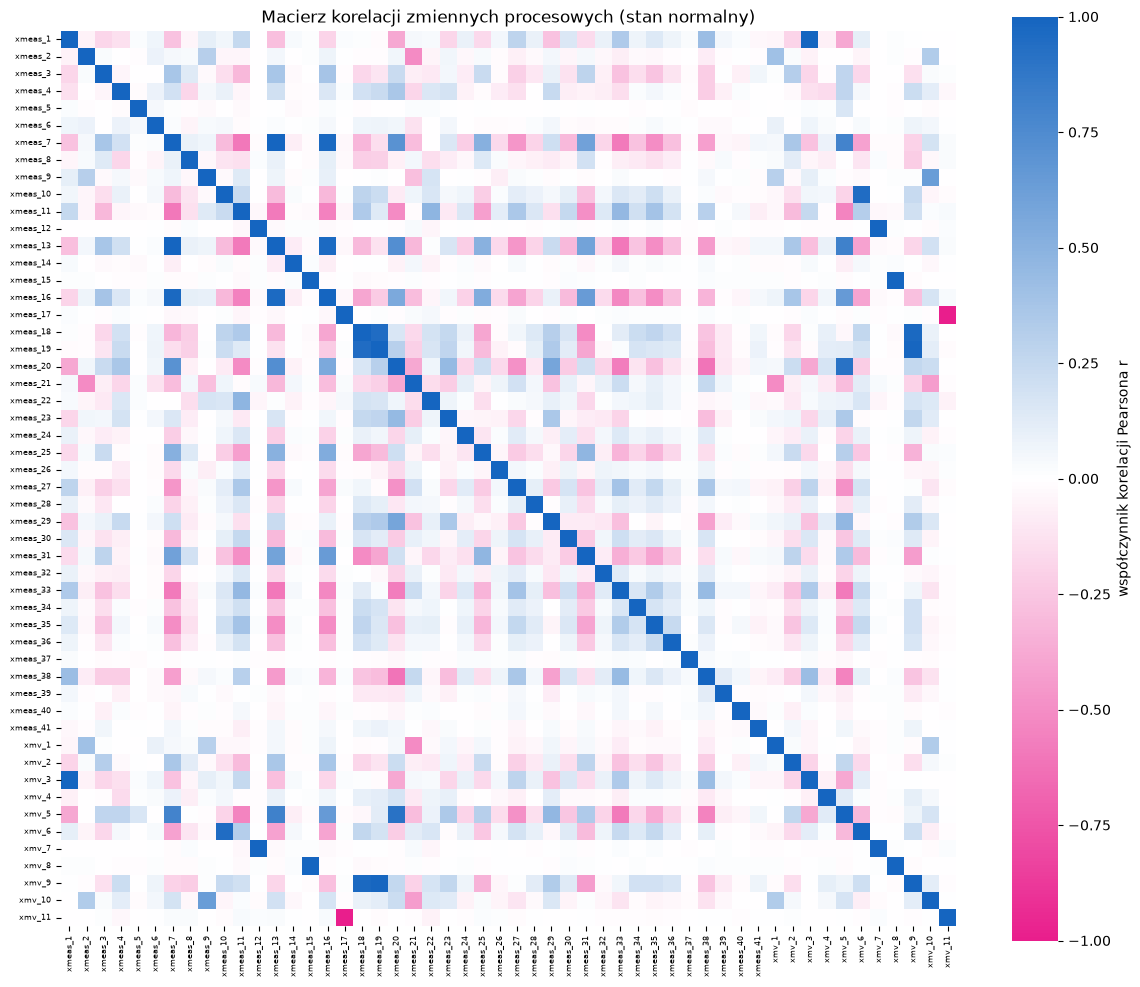

In [14]:
from matplotlib.colors import LinearSegmentedColormap

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

COLOR_PINK = globals().get("COLOR_PINK", "#E91E8C")
COLOR_BLUE = globals().get("COLOR_BLUE", "#1565C0")
COLOR_GREEN = globals().get("COLOR_GREEN", "#2E7D32")

cmap_corr = LinearSegmentedColormap.from_list(
    "pink_white_blue", [COLOR_PINK, "white", COLOR_BLUE]
)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    corr,
    cmap=cmap_corr,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "współczynnik korelacji Pearsona r"},
    ax=ax,
)
ax.set_title("Macierz korelacji zmiennych procesowych (stan normalny)")
ax.tick_params(axis="both", labelsize=6)
plt.tight_layout()

fig_path = FIG_DIR / "corr_heatmap_normal.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()

### 3.3. Wybór 4 zmiennych do analizy szczegółowej

Zapisano: figures/corr_heatmap_selected4.png


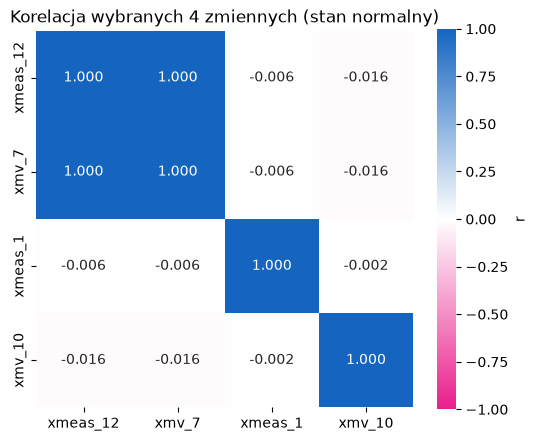

Podstawowe statystyki (stan normalny):
             mean   median     std      min      max  skewness
xmeas_12  49.9905  49.9930  1.0031  46.4820  53.5340   -0.0248
xmv_7     38.0719  38.0780  2.9521  27.7480  48.4990   -0.0248
xmeas_1    0.2504   0.2507  0.0309   0.1313   0.3632   -0.0400
xmv_10    41.1017  41.1030  0.5448  38.5860  43.1170    0.0106


In [15]:
SELECTED_DETAIL = ["xmeas_12", "xmv_7", "xmeas_1", "xmv_10"]
corr_sel = corr.loc[SELECTED_DETAIL, SELECTED_DETAIL]

COLOR_PINK = globals().get("COLOR_PINK", "#E91E8C")
COLOR_BLUE = globals().get("COLOR_BLUE", "#1565C0")
cmap_corr = LinearSegmentedColormap.from_list(
    "pink_white_blue", [COLOR_PINK, "white", COLOR_BLUE]
)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    corr_sel,
    cmap=cmap_corr,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".3f",
    square=True,
    cbar_kws={"label": "r"},
    ax=ax,
)
ax.set_title("Korelacja wybranych 4 zmiennych (stan normalny)")
plt.tight_layout()

fig_path = Path("figures") / "corr_heatmap_selected4.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()

print("Podstawowe statystyki (stan normalny):")
print(stats.loc[SELECTED_DETAIL, ["mean", "median", "std", "min", "max", "skewness"]].round(4).to_string())

### Histogramy (stan normalny)

Rozkłady wybranych 4 zmiennych. Osobne skale ze względu na różne rzędy wielkości.

Zapisano: figures/detail_hist_normal.png


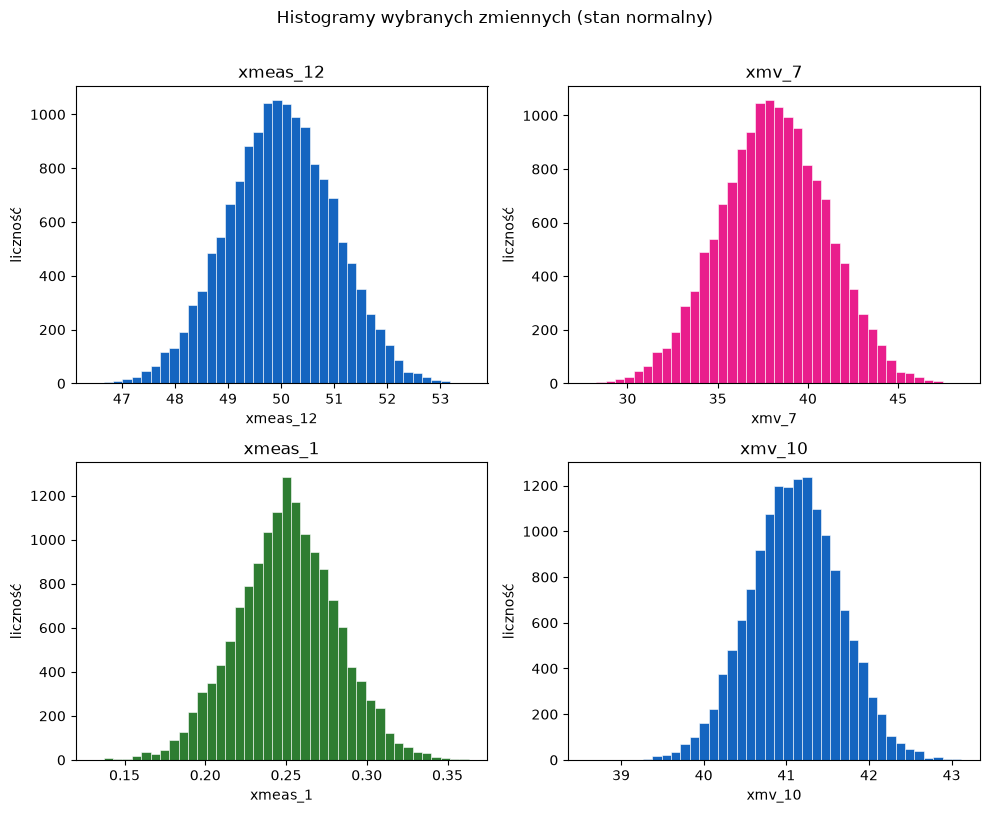

In [16]:
COLOR_PINK = globals().get("COLOR_PINK", "#E91E8C")
COLOR_BLUE = globals().get("COLOR_BLUE", "#1565C0")
COLOR_GREEN = globals().get("COLOR_GREEN", "#2E7D32")
DETAIL_COLORS = [COLOR_BLUE, COLOR_PINK, COLOR_GREEN, COLOR_BLUE]

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col, color in zip(axes.ravel(), SELECTED_DETAIL, DETAIL_COLORS):
    ax.hist(train_normal[col], bins=40, color=color, edgecolor="white", linewidth=0.4)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("liczność")
fig.suptitle("Histogramy wybranych zmiennych (stan normalny)", y=1.01)
plt.tight_layout()
fig_path = FIG_DIR / "detail_hist_normal.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()

### Wykresy pudełkowe (stan normalny)

Osobne osie dla każdej zmiennej ze względu na różnice skal.

Zapisano: figures/detail_box_normal.png


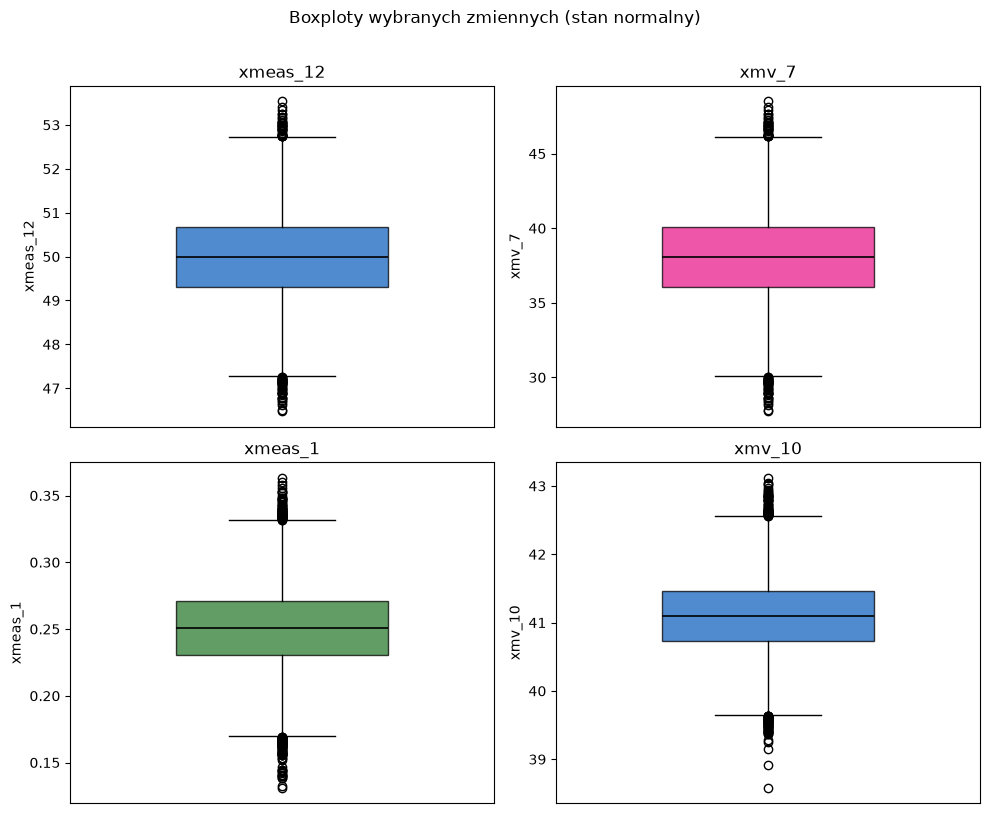

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col, color in zip(axes.ravel(), SELECTED_DETAIL, DETAIL_COLORS):
    bp = ax.boxplot(
        train_normal[col],
        orientation="vertical",
        patch_artist=True,
        widths=0.5,
    )
    for patch in bp["boxes"]:
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    for median in bp["medians"]:
        median.set_color("black")
        median.set_linewidth(1.2)
    ax.set_title(col)
    ax.set_xticks([])
    ax.set_ylabel(col)
fig.suptitle("Boxploty wybranych zmiennych (stan normalny)", y=1.01)
plt.tight_layout()
fig_path = FIG_DIR / "detail_box_normal.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()

### Scatter: para silna vs para słaba

- lewy: `xmeas_12` vs `xmv_7` (`r ~ 1`)
- prawy: `xmeas_1` vs `xmv_10` (`r ~ 0`)

Zapisano: figures/detail_scatter_normal.png


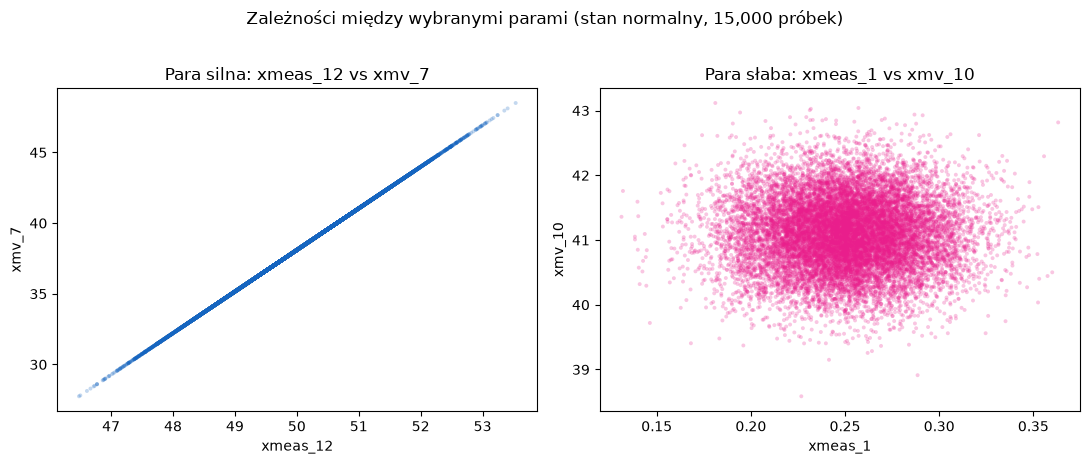

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(
    train_normal["xmeas_12"], train_normal["xmv_7"],
    s=8, alpha=0.25, color=COLOR_BLUE, edgecolors="none",
)
axes[0].set_xlabel("xmeas_12")
axes[0].set_ylabel("xmv_7")
axes[0].set_title("Para silna: xmeas_12 vs xmv_7")

axes[1].scatter(
    train_normal["xmeas_1"], train_normal["xmv_10"],
    s=8, alpha=0.25, color=COLOR_PINK, edgecolors="none",
)
axes[1].set_xlabel("xmeas_1")
axes[1].set_ylabel("xmv_10")
axes[1].set_title("Para słaba: xmeas_1 vs xmv_10")

fig.suptitle(
    f"Zależności między wybranymi parami (stan normalny, {len(train_normal):,} próbek)",
    y=1.02,
)
plt.tight_layout()
fig_path = FIG_DIR / "detail_scatter_normal.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()

### 3.4. Porównanie stanu normalnego z awariami

Wybrane awarie (różne charaktery):
- **6** - utrata dopływu składnika A (step)
- **8** - losowe zmiany składu A, B, C (random)
- **15** - zacinanie zaworu wody chłodzącej

Analiza na zbiorze **testowym** (jeden przebieg: `simulationRun = 1`).
Awaria zaczyna się od `sample = 160` (pionowa linia na wykresach).

In [19]:
FAULTS_COMPARE = [6, 8, 15]
RUN_ID = 1
FAULT_START = 160

COLOR_PINK = globals().get("COLOR_PINK", "#E91E8C")
COLOR_BLUE = globals().get("COLOR_BLUE", "#1565C0")
COLOR_GREEN = globals().get("COLOR_GREEN", "#2E7D32")

fault_styles = {
    0: ("stan normalny", COLOR_BLUE, 1.8),
    6: ("awaria 6 (step)", COLOR_PINK, 1.3),
    8: ("awaria 8 (random)", COLOR_GREEN, 1.3),
    15: ("awaria 15 (sticking)", "#6A1B9A", 1.3),
}

def get_run(df, fault, run=RUN_ID):
    out = df.loc[
        (df["faultNumber"] == fault) & (df["simulationRun"] == run),
        ["sample", *SELECTED_DETAIL],
    ].sort_values("sample")
    return out

runs = {f: get_run(test, f) for f in [0, *FAULTS_COMPARE]}
for f, d in runs.items():
    print(f"fault={f}: {len(d)} próbek, sample {d['sample'].min()}…{d['sample'].max()}")

fault=0: 960 próbek, sample 1…960
fault=6: 960 próbek, sample 1…960
fault=8: 960 próbek, sample 1…960
fault=15: 960 próbek, sample 1…960


### Przebiegi czasowe wybranych zmiennych

Dla każdej zmiennej: stan normalny vs awarie 6, 8, 15.

Zapisano: figures/faults_timeseries_selected4.png


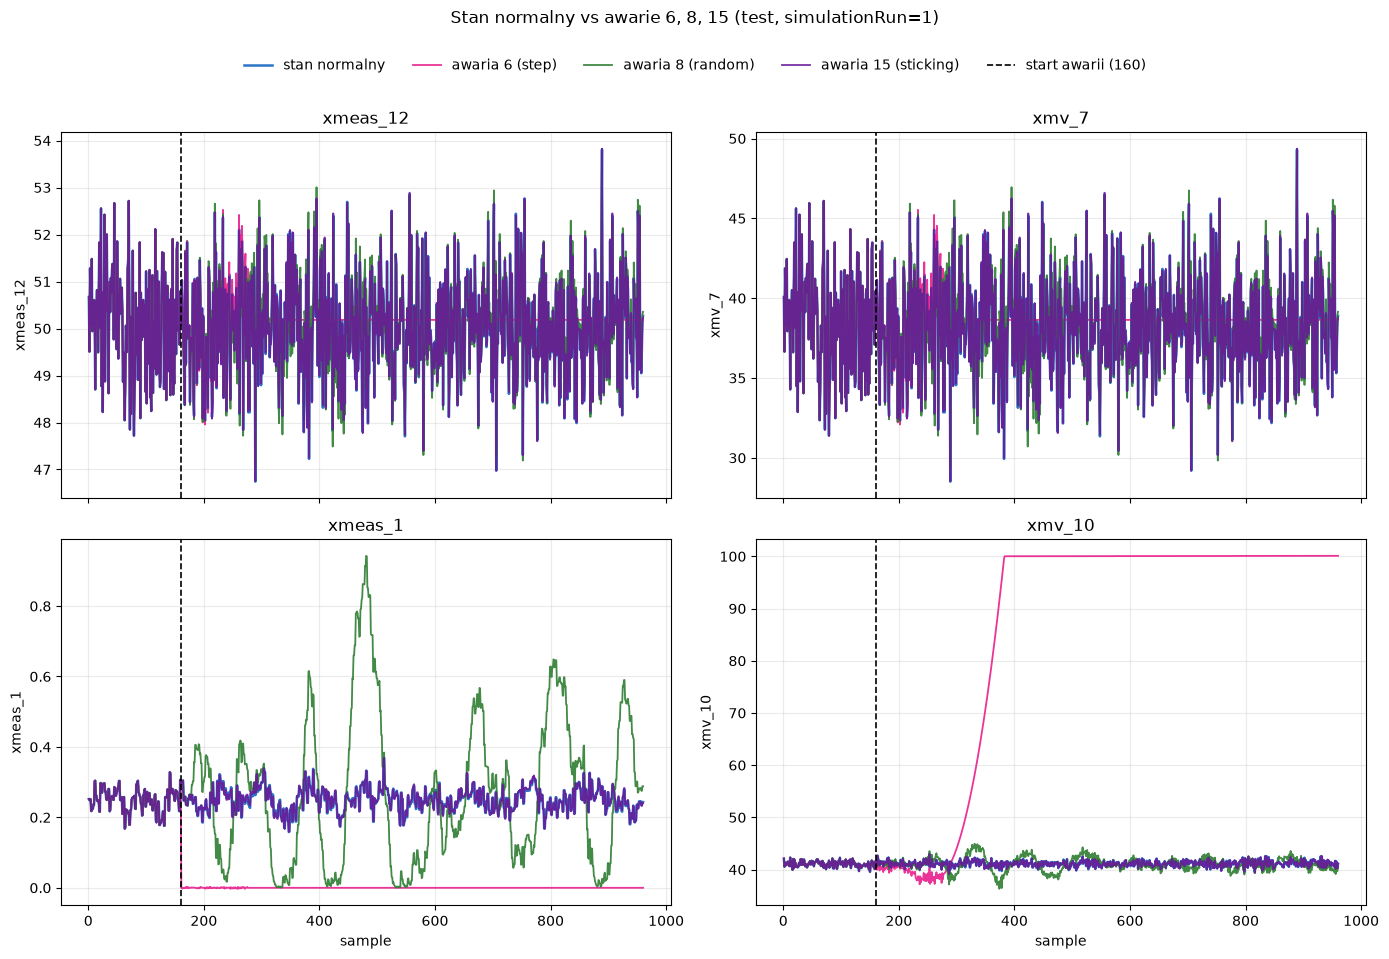

In [20]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

for ax, col in zip(axes.ravel(), SELECTED_DETAIL):
    for fault, (label, color, lw) in fault_styles.items():
        d = runs[fault]
        ax.plot(d["sample"], d[col], label=label, color=color, lw=lw, alpha=0.9)
    ax.axvline(FAULT_START, color="black", ls="--", lw=1.2, label="start awarii (160)" if col == SELECTED_DETAIL[0] else None)
    ax.set_title(col)
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.25)

axes[1, 0].set_xlabel("sample")
axes[1, 1].set_xlabel("sample")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Stan normalny vs awarie 6, 8, 15 (test, simulationRun=1)", y=1.06)
plt.tight_layout()
fig_path = FIG_DIR / "faults_timeseries_selected4.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()

### 3.5. Analiza ilościowa

Cel: wskazać, **które zmienne najbardziej różnicują** stan normalny od awarii 6/8/15
oraz sprawdzić, jak zmieniają się **zależności** między wybranymi zmiennymi.

Liczymy na zbiorze testowym, w oknie **po starcie awarii** (`sample >= 160`),
dla tego samego przebiegu (`simulationRun = 1`).

**Wybrane miary** (porównywalne między zmiennymi o różnych skalach):
1. **`|delta_mean| / std_normal`** - standaryzowana zmiana średniego poziomu
2. **`std_fault / std_normal`** - zmiana zmienności
3. **`max |x_fault - x_normal|`** - największe odchylenie od przebiegu normalnego w tym samym `sample`

In [21]:
FAULT_START = globals().get("FAULT_START", 160)
RUN_ID = globals().get("RUN_ID", 1)
FAULTS_COMPARE = globals().get("FAULTS_COMPARE", [6, 8, 15])


def get_run_cols(df, fault, cols, run=RUN_ID):
    return (
        df.loc[(df["faultNumber"] == fault) & (df["simulationRun"] == run), ["sample", *cols]]
        .sort_values("sample")
        .set_index("sample")
    )


normal_ts = get_run_cols(test, 0, SELECTED_DETAIL)
normal_post = normal_ts.loc[FAULT_START:]
base_std = normal_post.std().replace(0, np.nan)

rows = []
for fault in FAULTS_COMPARE:
    fault_ts = get_run_cols(test, fault, SELECTED_DETAIL)
    fault_post = fault_ts.loc[FAULT_START:]
    for col in SELECTED_DETAIL:
        dmean = fault_post[col].mean() - normal_post[col].mean()
        std_ratio = fault_post[col].std() / base_std[col]
        max_abs = (fault_post[col] - normal_post[col]).abs().max()
        rows.append(
            {
                "awaria": fault,
                "zmienna": col,
                "abs_dmean_over_std": abs(dmean) / base_std[col],
                "std_ratio": std_ratio,
                "max_abs_dev": max_abs,
                "dmean": dmean,
            }
        )

quant_sel = pd.DataFrame(rows)
print("Miary różnicujące (wybrane 4 zmienne, sample >= 160):")
display_cols = ["awaria", "zmienna", "abs_dmean_over_std", "std_ratio", "max_abs_dev"]
print(quant_sel[display_cols].round(3).to_string(index=False))

# LaTeX table
quant_tex = quant_sel[display_cols].rename(
    columns={
        "awaria": "Awaria",
        "zmienna": "Zmienna",
        "abs_dmean_over_std": "|delta_mean|/std",
        "std_ratio": "std_f/std_n",
        "max_abs_dev": "max|delta_x|",
    }
)
save_latex_table(
    quant_tex.set_index("Awaria"),
    TABLE_DIR / "quant_diff_selected4.tex",
    caption="Miary różnicujące stan normalny od awarii 6/8/15 dla wybranych zmiennych (test, sample >= 160).",
    label="tab:quant-diff",
    float_format="%.3f",
)
quant_tex

Miary różnicujące (wybrane 4 zmienne, sample >= 160):
 awaria  zmienna  abs_dmean_over_std  std_ratio  max_abs_dev
      6 xmeas_12               0.138      0.396        3.628
      6    xmv_7               0.138      0.396       10.675
      6  xmeas_1               7.538      0.326        0.369
      6   xmv_10              83.299     44.718       60.595
      8 xmeas_12               0.035      1.011        0.394
      8    xmv_7               0.035      1.011        1.159
      8  xmeas_1               0.607      6.282        0.610
      8   xmv_10               0.123      2.444        3.621
     15 xmeas_12               0.000      1.001        0.082
     15    xmv_7               0.000      1.001        0.243
     15  xmeas_1               0.002      1.008        0.007
     15   xmv_10               0.001      1.010        0.206
LaTeX: tables/quant_diff_selected4.tex


,Awaria,Zmienna,|delta_mean|/std,std_f/std_n,max|delta_x|
0,6,xmeas_12,0.137855,0.396336,3.62800
1,6,xmv_7,0.137998,0.396337,10.67500
2,6,xmeas_1,7.537715,0.326110,0.36865
3,6,xmv_10,83.299313,44.718344,60.59500
4,8,xmeas_12,0.035410,1.010791,0.39400
5,8,xmv_7,0.035422,1.010802,1.15900
6,8,xmeas_1,0.606677,6.281665,0.60980
7,8,xmv_10,0.123285,2.443765,3.62100
8,15,xmeas_12,0.000067,1.000989,0.08200
9,15,xmv_7,0.000061,1.000989,0.24300


### Wykres: standaryzowana zmiana średniej

Im wyższy słupek `|delta_mean|/std_normal`, tym mocniej awaria przesuwa poziom zmiennej względem stanu normalnego.

Zapisano: figures/quant_dmean_std_selected4.png


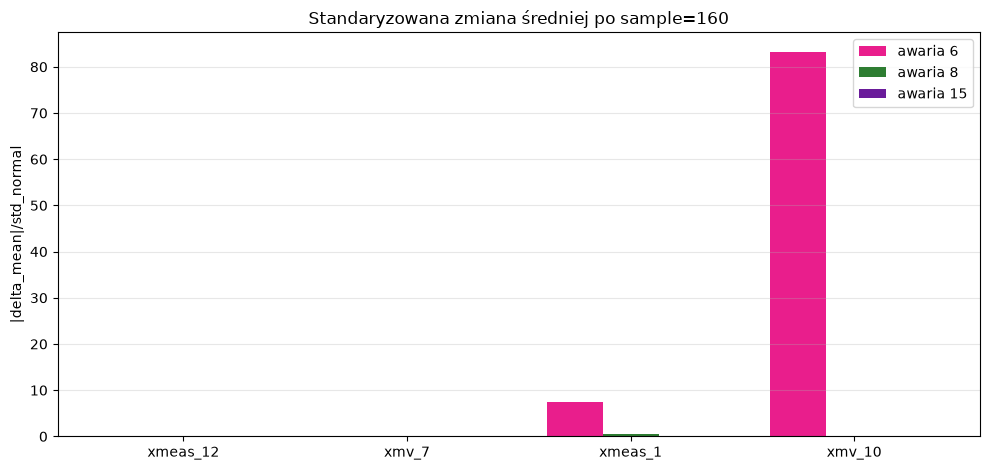

In [22]:
COLOR_PINK = globals().get("COLOR_PINK", "#E91E8C")
COLOR_BLUE = globals().get("COLOR_BLUE", "#1565C0")
COLOR_GREEN = globals().get("COLOR_GREEN", "#2E7D32")
fault_colors = {6: COLOR_PINK, 8: COLOR_GREEN, 15: "#6A1B9A"}

pivot = quant_sel.pivot(index="zmienna", columns="awaria", values="abs_dmean_over_std")
pivot = pivot.reindex(SELECTED_DETAIL)

x = np.arange(len(SELECTED_DETAIL))
width = 0.25
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, fault in enumerate(FAULTS_COMPARE):
    ax.bar(
        x + (i - 1) * width,
        pivot[fault].values,
        width=width,
        label=f"awaria {fault}",
        color=fault_colors[fault],
    )
ax.set_xticks(x)
ax.set_xticklabels(SELECTED_DETAIL)
ax.set_ylabel("|delta_mean|/std_normal")
ax.set_title("Standaryzowana zmiana średniej po sample=160")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
fig_path = Path("figures") / "quant_dmean_std_selected4.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()

### Ranking: zmienne najbardziej różnicujące ze wszystkich 52

Top 5 zmiennych według `|delta_mean|/std_normal` osobno dla każdej awarii.

In [23]:
normal_all = get_run_cols(test, 0, process_cols)
normal_all_post = normal_all.loc[FAULT_START:]
base_std_all = normal_all_post.std().replace(0, np.nan)

top_rows = []
for fault in FAULTS_COMPARE:
    fault_all = get_run_cols(test, fault, process_cols).loc[FAULT_START:]
    score = ((fault_all.mean() - normal_all_post.mean()).abs() / base_std_all).sort_values(ascending=False)
    print(f"=== Awaria {fault}: top 5 wg |delta_mean|/std ===")
    print(score.head(5).round(3).to_string())
    print()
    for rank, (var, val) in enumerate(score.head(5).items(), start=1):
        top_rows.append({"awaria": fault, "rank": rank, "zmienna": var, "abs_dmean_over_std": val})

top_df = pd.DataFrame(top_rows)
save_latex_table(
    top_df.set_index("awaria"),
    TABLE_DIR / "quant_top5_allvars.tex",
    caption="Top 5 zmiennych najbardziej różnicujących stan normalny od awarii (wg |Δmean|/std, test, po sample 160).",
    label="tab:quant-top5",
    float_format="%.3f",
)
top_df

=== Awaria 6: top 5 wg |delta_mean|/std ===
xmv_10      83.299
xmeas_16    50.344
xmeas_7     37.537
xmeas_13    34.827
xmv_5       34.537

=== Awaria 8: top 5 wg |delta_mean|/std ===
xmeas_34    7.340
xmeas_28    5.561
xmv_6       3.897
xmeas_10    3.832
xmv_9       3.572

=== Awaria 15: top 5 wg |delta_mean|/std ===
xmv_9       0.014
xmeas_19    0.014
xmeas_9     0.012
xmeas_18    0.012
xmeas_22    0.006

LaTeX: tables/quant_top5_allvars.tex


,awaria,rank,zmienna,abs_dmean_over_std
0,6,1,xmv_10,83.299313
1,6,2,xmeas_16,50.344132
2,6,3,xmeas_7,37.536888
3,6,4,xmeas_13,34.827246
4,6,5,xmv_5,34.536806
5,8,1,xmeas_34,7.340100
6,8,2,xmeas_28,5.561007
7,8,3,xmv_6,3.897493
8,8,4,xmeas_10,3.831566
9,8,5,xmv_9,3.572309


### Zmiana zależności (korelacje 4 zmiennych po sample 160)

Porównanie macierzy korelacji: stan normalny vs awarie.

Zapisano: figures/quant_corr_states_selected4.png


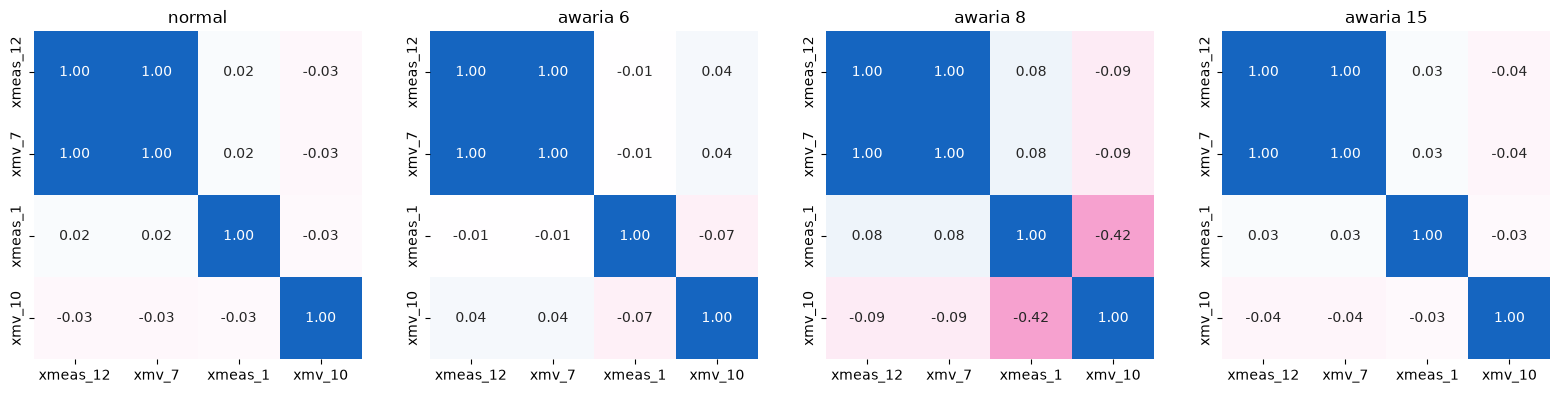

In [24]:
cmap_corr = LinearSegmentedColormap.from_list(
    "pink_white_blue",
    [globals().get("COLOR_PINK", "#E91E8C"), "white", globals().get("COLOR_BLUE", "#1565C0")],
)

corr_states = {
    "normal": normal_post[SELECTED_DETAIL].corr(),
}
for fault in FAULTS_COMPARE:
    corr_states[f"awaria {fault}"] = (
        get_run_cols(test, fault, SELECTED_DETAIL).loc[FAULT_START:, SELECTED_DETAIL].corr()
    )

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, mat) in zip(axes, corr_states.items()):
    sns.heatmap(
        mat, cmap=cmap_corr, vmin=-1, vmax=1, center=0,
        annot=True, fmt=".2f", square=True, cbar=False, ax=ax,
    )
    ax.set_title(name)
plt.tight_layout()
fig_path = Path("figures") / "quant_corr_states_selected4.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()